# GDPR Enforcement Tracker — Violation Analysis

Source: [enforcementtracker.com](https://www.enforcementtracker.com) (CMS Law), exported 2026-06-23.  
Filter applied: all countries, all sectors, 01/01/2018–21/01/2026 → **3,172 fines** with complete data.

Produces:
- **Figure 1** (`gdpr_violations_type_june_2026.png`): Total fines by violation type — replaces `gdpr_violations_type_21_Jan_2026.png`
- **Figure 2** (`gdpr_violations_by_year_june_2026.png`): Stacked fines by violation type × year

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Load CSVs — skip 3 footer lines (blank + 2 source attribution lines)
df_total = pd.read_csv('enforcement-by-violation.csv', skipfooter=3, engine='python')
df_year_raw = pd.read_csv('enforcement-violation-by-year.csv', skipfooter=3, engine='python')

# Separate data rows from the Total row
df_year = df_year_raw[df_year_raw['Violation type'] != 'Total'].reset_index(drop=True)
df_year_total_row = df_year_raw[df_year_raw['Violation type'] == 'Total'].iloc[0]

print(df_total[['Group', 'Count']].to_string(index=False))
print(f"\nTotal fines: {df_total['Count'].sum()} (category counts; one fine can span multiple)")

/Users/abhashshrestha/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


                                                                            Group  Count
                                     Insufficient legal basis for data processing    960
                           Non-compliance with general data processing principles    787
Insufficient technical and organisational measures to ensure information security    591
                                  Insufficient fulfilment of data subjects rights    314
                               Insufficient fulfilment of information obligations    209
                              Insufficient cooperation with supervisory authority    175
                  Insufficient fulfilment of data breach notification obligations     53
                                                                          Unknown     30
                              Insufficient involvement of data protection officer     26
                                           Insufficient data processing agreement     19
                     

## Figure 1: Total Fines by Violation Type

Replicates the style of the original `gdpr_violations_type_21_Jan_2026.png` with updated June 2026 data.

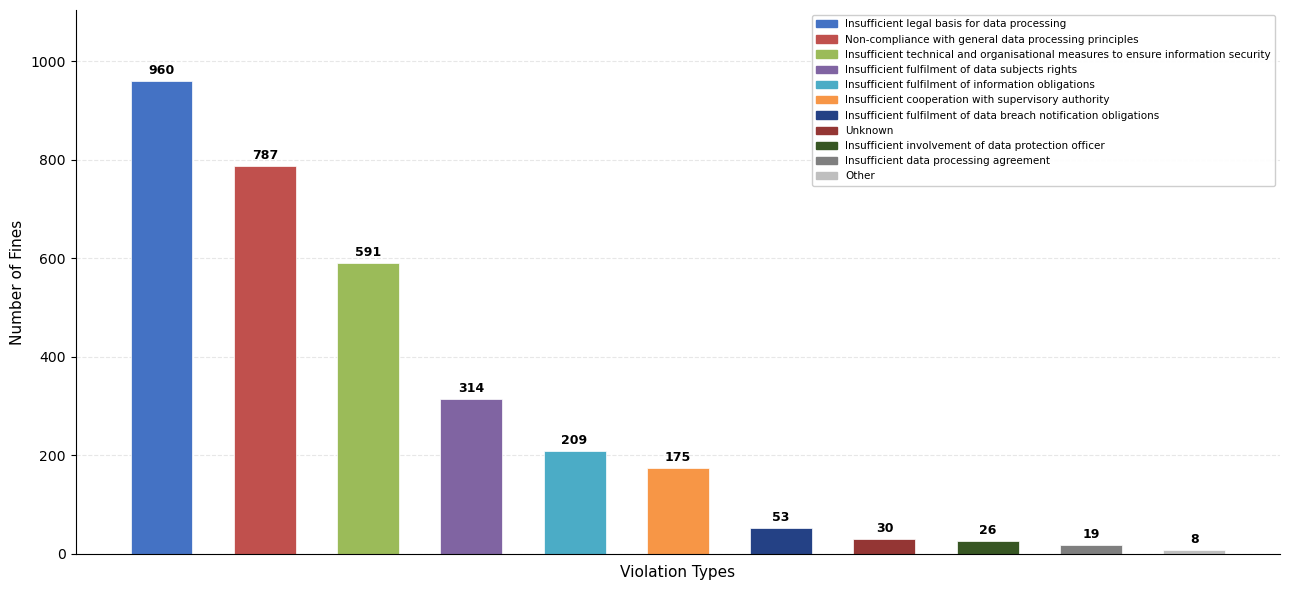

Saved: gdpr_violations_type_june_2026.png


In [2]:
# Color palette matching the original figure
COLORS = [
    '#4472C4',  # Blue         — Insufficient legal basis
    '#C0504D',  # Red          — Non-compliance with principles
    '#9BBB59',  # Green        — Insufficient TOMs
    '#8064A2',  # Purple       — Insufficient data subjects rights
    '#4BACC6',  # Cyan         — Insufficient information obligations
    '#F79646',  # Orange       — Insufficient cooperation with SA
    '#244185',  # Dark blue    — Insufficient data breach notification
    '#943634',  # Dark red     — Unknown
    '#375623',  # Dark green   — Insufficient DPO involvement
    '#7F7F7F',  # Gray         — Insufficient data processing agreement
    '#BFBFBF',  # Light gray   — Other
]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(
    range(len(df_total)),
    df_total['Count'],
    color=COLORS[:len(df_total)],
    width=0.6,
    edgecolor='white',
    linewidth=0.5
)

# Value labels on top of each bar
for bar, val in zip(bars, df_total['Count']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        str(val),
        ha='center', va='bottom',
        fontsize=9, fontweight='bold'
    )

# Axes
ax.set_xticks([])
ax.set_xlabel('Violation Types', fontsize=11, labelpad=8)
ax.set_ylabel('Number of Fines', fontsize=11)
ax.set_ylim(0, df_total['Count'].max() * 1.15)
ax.yaxis.grid(True, alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
patches = [
    mpatches.Patch(color=COLORS[i], label=row['Group'])
    for i, row in df_total.iterrows()
]
ax.legend(
    handles=patches,
    fontsize=7.5,
    loc='upper right',
    framealpha=0.95,
    frameon=True,
    edgecolor='#cccccc'
)

plt.tight_layout()
plt.savefig('gdpr_violations_type_june_2026.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: gdpr_violations_type_june_2026.png')

## Figure 2: Fines by Violation Type per Year

Year columns in the CSV are sorted by total count (not chronologically). This cell reorders them 2018→2026.  
The `Other` column in the CSV represents fines with year ≤2018 or undated — relabelled as `≤2018`.

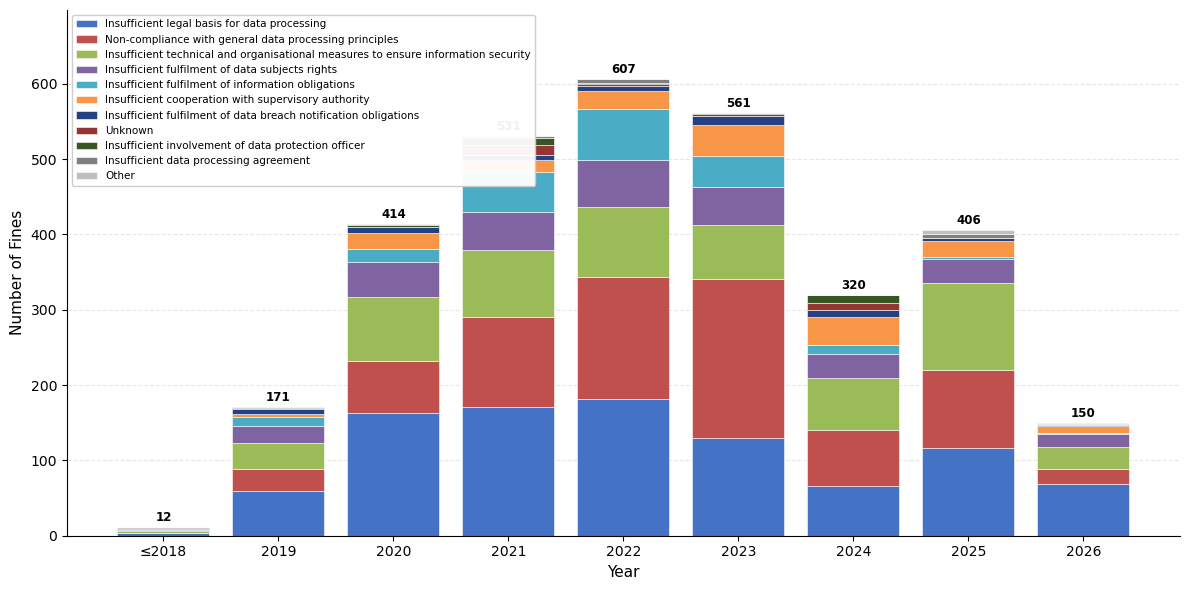

Saved: gdpr_violations_by_year_june_2026.png


In [3]:
# Reorder year columns chronologically
year_cols_csv   = ['Other', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']
year_labels_plt = ['≤2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']

fig, ax = plt.subplots(figsize=(12, 6))

bottom = np.zeros(len(year_cols_csv))
for i, (_, row) in enumerate(df_year.iterrows()):
    vals = np.array([row[col] for col in year_cols_csv], dtype=float)
    ax.bar(
        year_labels_plt, vals, bottom=bottom,
        color=COLORS[i % len(COLORS)],
        label=row['Violation type'],
        edgecolor='white', linewidth=0.4
    )
    bottom += vals

# Total count labels on top of each stacked bar
for j, col in enumerate(year_cols_csv):
    total_val = int(df_year_total_row[col])
    if total_val > 0:
        ax.text(
            j, bottom[j] + 4, str(total_val),
            ha='center', va='bottom', fontsize=8.5, fontweight='bold'
        )

# Axes
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Number of Fines', fontsize=11)
ax.set_ylim(0, bottom.max() * 1.15)
ax.yaxis.grid(True, alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels,
    fontsize=7.5,
    loc='upper left',
    framealpha=0.95,
    frameon=True,
    edgecolor='#cccccc'
)

plt.tight_layout()
plt.savefig('gdpr_violations_by_year_june_2026.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: gdpr_violations_by_year_june_2026.png')

## Figure 3: Enforcement Trends Over Time (Count + Total Fine Amount)

Dual-axis chart: bars show annual fine count (left axis); smoothed spline shows total fine amount in € billion (right axis).  
Data source: Analytics tab → Count/Total € by Year (all violation types combined), enforcementtracker.com, exported 2026-06-23.  
**Note:** 2026 is a partial year (January–June only) — hatched bar + annotation.

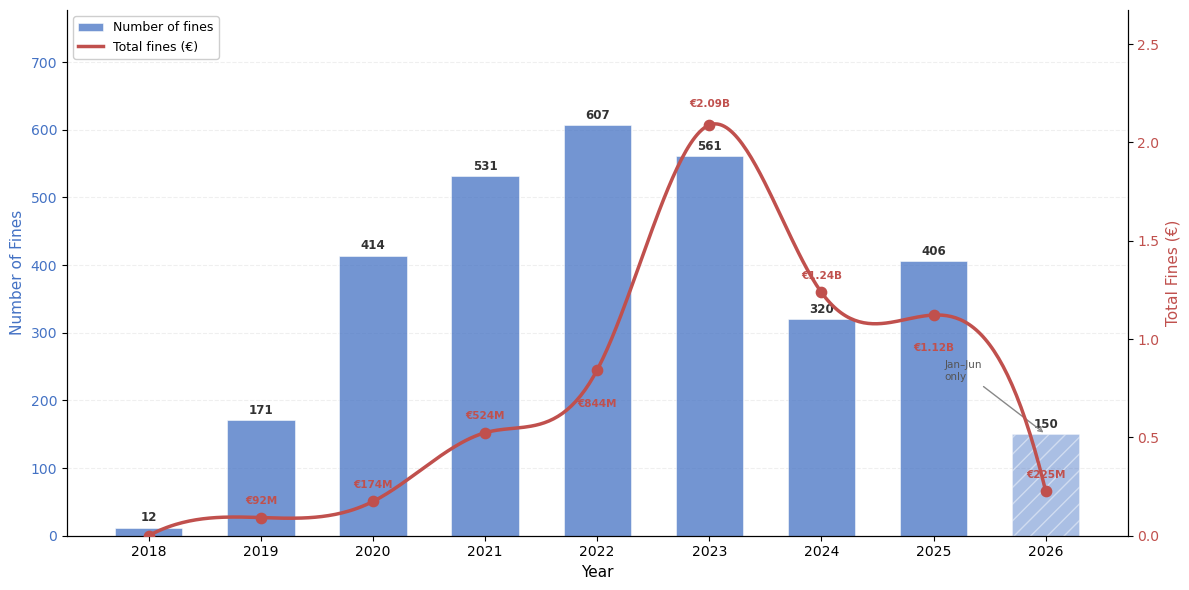

Saved: gdpr_enforcement_trends_june_2026.png


In [5]:
from scipy.interpolate import make_interp_spline

# Data from Analytics tab — Count by Year (all violation types, all countries)
# Source: enforcementtracker.com, exported 2026-06-24
years      = [2018,  2019,  2020,  2021,  2022,  2023,  2024,  2025,  2026]
counts     = [12,    171,   414,   531,   607,   561,   320,   406,   150]
totals_eur = [
    458_688,
    92_313_564,
    174_208_409,
    523_742_503,
    843_905_565,
    2_088_270_232,
    1_236_745_115,
    1_121_980_317,
    225_024_232,   # partial year: Jan–Jun 2026
]
totals_b = [t / 1e9 for t in totals_eur]

partial_idx = years.index(2026)

def fmt_amount(val_b):
    """Use M if < 1B, B if >= 1B."""
    if val_b < 1.0:
        return f'€{val_b * 1000:.0f}M'
    else:
        return f'€{val_b:.2f}B'

fig, ax1 = plt.subplots(figsize=(12, 6))

# --- Left axis: bar chart of fine counts ---
bars = ax1.bar(
    years, counts,
    color='#4472C4', width=0.6, alpha=0.75,
    edgecolor='white', linewidth=0.5,
    label='Number of fines'
)
# Hatch 2026 bar to signal partial year
bars[partial_idx].set_hatch('//')
bars[partial_idx].set_alpha(0.45)

# Count labels on bars
for bar, val in zip(bars, counts):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(val),
        ha='center', va='bottom',
        fontsize=8.5, fontweight='bold', color='#333333'
    )

ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Number of Fines', fontsize=11, color='#4472C4')
ax1.tick_params(axis='y', labelcolor='#4472C4')
ax1.set_ylim(0, max(counts) * 1.28)
ax1.yaxis.grid(True, alpha=0.2, linestyle='--')
ax1.set_axisbelow(True)
ax1.spines['top'].set_visible(False)
ax1.set_xticks(years)

# --- Right axis: spline of total fine amount ---
ax2 = ax1.twinx()

x_pts    = np.array(years, dtype=float)
y_pts    = np.array(totals_b)
x_smooth = np.linspace(x_pts[0], x_pts[-1], 400)

spline   = make_interp_spline(x_pts, y_pts, k=3)
y_smooth = np.clip(spline(x_smooth), 0, None)

ax2.plot(x_smooth, y_smooth, color='#C0504D', linewidth=2.5, label='Total fines (€)')
ax2.scatter(years, totals_b, color='#C0504D', s=55, zorder=5)

# Fine amount labels — M if < 1B, B if >= 1B
label_offsets = {
    2018: 0.06,
    2019: 0.06,
    2020: 0.06,
    2021: 0.06,
    2022: -0.15,
    2023:  0.08,
    2024:  0.06,
    2025: -0.14,
    2026:  0.06,
}
for yr, tb in zip(years, totals_b):
    if tb < 0.001:
        continue  # skip 2018
    offset = label_offsets.get(yr, 0.06)
    va = 'bottom' if offset >= 0 else 'top'
    ax2.text(
        yr, tb + offset,
        fmt_amount(tb),
        ha='center', va=va,
        fontsize=7.5, color='#C0504D', fontweight='bold'
    )

ax2.set_ylabel('Total Fines (€)', fontsize=11, color='#C0504D')
ax2.tick_params(axis='y', labelcolor='#C0504D')
ax2.set_ylim(0, max(totals_b) * 1.28)
ax2.spines['top'].set_visible(False)

# Partial-year annotation for 2026
ax1.annotate(
    'Jan–Jun\nonly',
    xy=(2026, counts[partial_idx]),
    xytext=(2025.1, counts[partial_idx] + 80),
    fontsize=7.5, color='#555555',
    arrowprops=dict(arrowstyle='->', color='#888888', lw=1.0)
)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2, labels1 + labels2,
    loc='upper left', fontsize=9,
    framealpha=0.95, edgecolor='#cccccc'
)

plt.tight_layout()
plt.savefig('gdpr_enforcement_trends_june_2026.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: gdpr_enforcement_trends_june_2026.png')